In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
X_test.shape

(10000, 28, 28)

In [4]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

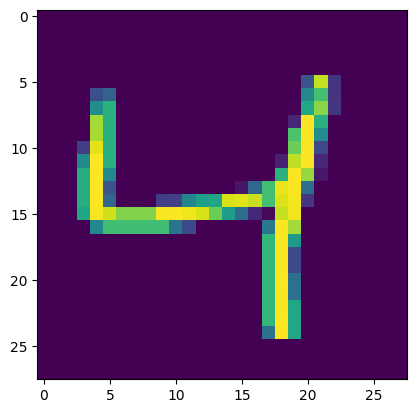

In [5]:
import matplotlib.pyplot as plt
plt.imshow(X_train[2])

In [6]:
X_train = X_train / 255
X_test = X_test / 255

In [7]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [8]:
model = Sequential()

model.add(Flatten(input_shape=(28, 28))) # convert data into 1d array
model.add(Dense(128, activation="relu"))
model.add(Dense(32, activation="relu"))
model.add(Dense(10, activation="softmax"))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(loss="sparse_categorical_crossentropy", optimizer="Adam")

In [11]:
history = model.fit(X_train, y_train, epochs=25, validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.2912 - val_loss: 0.1428
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1240 - val_loss: 0.1174
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0857 - val_loss: 0.1098
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0633 - val_loss: 0.0963
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0489 - val_loss: 0.1022
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0394 - val_loss: 0.1099
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0325 - val_loss: 0.0899
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0262 - val_loss: 0.1071
Epoch 9/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0215 - val_loss: 0.1075
Epoch 10/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0195 - val_loss: 0.1115
Epoch 11/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0172 - val_loss: 0.1249
Epoch 12/25
1500/1500 ━━━━━━━━

In [12]:
y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [13]:
y_prob

array([[7.64501127e-16, 3.53469229e-12, 1.27583209e-12, ...,
        1.00000000e+00, 3.84061713e-14, 3.36004488e-11],
       [1.37120939e-22, 2.30650297e-13, 1.00000000e+00, ...,
        1.32187465e-26, 2.25027397e-12, 2.46616217e-32],
       [2.57433658e-12, 9.99999404e-01, 2.03700723e-09, ...,
        9.34828881e-10, 6.40553935e-07, 6.42888791e-14],
       ...,
       [1.49228227e-30, 1.04809898e-15, 4.39141363e-25, ...,
        2.52960312e-15, 2.81711945e-19, 1.14109104e-11],
       [4.55883793e-21, 1.29725292e-25, 5.81339273e-26, ...,
        6.74401232e-19, 1.21060024e-15, 2.17390837e-24],
       [9.23523199e-16, 2.89609077e-23, 5.11272422e-16, ...,
        3.24131586e-23, 3.59556189e-17, 1.11301885e-20]], dtype=float32)

In [14]:
y_pred = y_prob.argmax(axis=1)

In [15]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9761

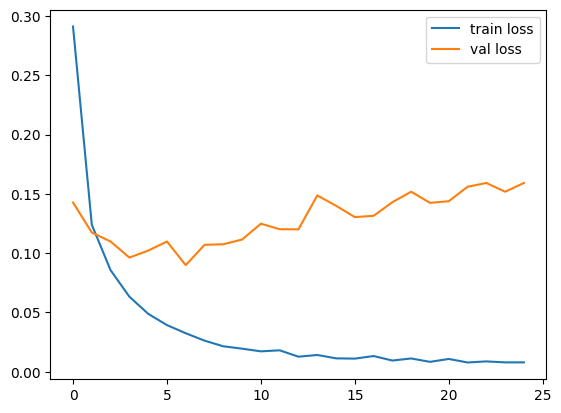

In [16]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.show()

In [18]:
history.history

{'loss': [0.2912496030330658,
  0.12399215996265411,
  0.08566613495349884,
  0.0633251816034317,
  0.04888797923922539,
  0.03935352340340614,
  0.032496627420186996,
  0.026241984218358994,
  0.021488023921847343,
  0.019465822726488113,
  0.017226319760084152,
  0.018084170296788216,
  0.012702690437436104,
  0.014156637713313103,
  0.011310841888189316,
  0.011086513288319111,
  0.013251970522105694,
  0.00946373026818037,
  0.0112150888890028,
  0.008358120918273926,
  0.010802188888192177,
  0.007828748784959316,
  0.008742925710976124,
  0.007907154969871044,
  0.007923591881990433],
 'val_loss': [0.14276370406150818,
  0.11744412034749985,
  0.10984713584184647,
  0.09631545841693878,
  0.1021989956498146,
  0.10986562818288803,
  0.08993438631296158,
  0.10706701874732971,
  0.10754269361495972,
  0.11154750734567642,
  0.12487898766994476,
  0.12023816257715225,
  0.12012408673763275,
  0.14872775971889496,
  0.1400085687637329,
  0.1304447501897812,
  0.13154539465904236,
  

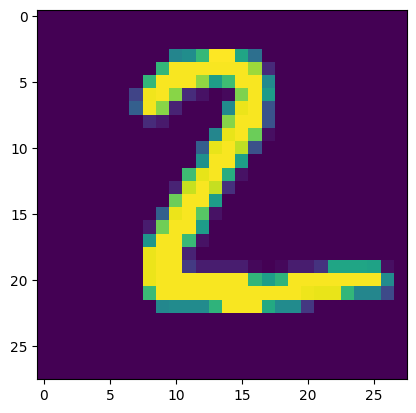

In [25]:
plt.imshow(X_test[1])

In [24]:
model.predict(X_test[1].reshape(1, 28, 28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


array([2])